# Food and body-image themes in annotated social media posts
**INFO 2950 · Phase II · Parts 1 and 2**  
**Group:** Anya Choudhary; Zara Islam (zsi2); Riya Gupta (rg823); April Vorontsova (vv252).

Github repo: AnyaChoudhary/info2950-fall2026-project

## 1. Research questions
Our main question is: What food and body-image concerns appear in these posts, and how do they relate to other features of the posts?

1. Which concerns and content features appear in each dataset, and how common are they among posts where each label applies?
2. Among Twitter posts about eating disorders or body image, are shape-concern and eating-concern labels associated?
3. In EDTT, is a restraint label associated with audio valence after accounting for whether the post is a video or photo slideshow?

Phase II explores question 1. Questions 2 and 3 are planned for the final report and have not been tested. The files describe posts, so they cannot show algorithm effects, engagement effects, diagnoses, or changes in a person's relationship with food. Recovery and social comparison are not measured consistently enough to use as shared outcomes.

Twitter provides a larger sample of coded posts; EDTT provides a smaller sample with visual and audio features. We analyze them separately because their collection methods and labels differ.

### Questions and data
| Question | Dataset | What we measure | Possible predictors | Posts included |
|---|---|---|---|---|
| 1 | Twitter and EDTT, separately | Counts and percentages for each label | None; descriptive summaries | Depends on the label's coding rules |
| 2 | Twitter | Eating concern (`eating`) | Shape concern (`shape`) | 2,584 related posts |
| 3 | EDTT | Audio valence (`audio_valence`, 0 to 1) | Restraint (`ede_restraint`) and post format (`type`) | 79 posts with nonblank EDE text |

All measures come from released fields or labels extracted directly from them. For question 3, the planned model will code `type` as photos versus video; a separate `photos` column has not been added to the cleaned data. None of these questions requires viewer, engagement, or exposure data.

## 2. Data collection and cleaning
### 2.1 Data sources
The source files were downloaded on October 15, 2026. Downloads occurred outside the notebook, as the rubric requests collection descriptions but no collection code. Original bytes are retained under data/raw/; the manifest records URLs and SHA-256 checksums. The same unchanged files are hosted in the [project GitHub raw-data folder](https://github.com/AnyaChoudhary/info2950-fall2026-project/tree/905e574351e821300dc5b199747216a3bd630e1b/data/raw), pinned to the verified upload commit so reviewers can retrieve the exact inputs.

Twitter: Cavazos-Rehg et al. (2019), [PLOS ONE article](https://doi.org/10.1371/journal.pone.0207506), [S1 Dataset](https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0207506.s002&type=supplementary), and [S1 Codebook](https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0207506.s003&type=supplementary). The study sampled 3,000 English-language posts from a keyword-selected January 2015 corpus. The release supplies de-identified codes. The original post text is not included. The published methods describe trained coders and adjudication.

TikTok: Shaveet, Viranda, and Choudhury (2026), [EDTT v2](https://doi.org/10.5281/zenodo.19749827), [public CSV](https://zenodo.org/records/19749827/files/EDTT_public.csv?download=1), and [data dictionary](https://edenshaveet.github.io/EDTT/). This is a curated, expert-annotated pro-ED content sample assembled through text retrieval and recommendation surfacing. Private post identifiers and transcripts are withheld. The record was published in April 2026; the proposed 2024–2025 collection window was not verified in the public documentation inspected and is not assumed here.

Project files, cleaning outputs, and documentation are available in the [GitHub repository](https://github.com/AnyaChoudhary/info2950-fall2026-project).

No scraping, individual contact, account identification, or new annotation was performed. No API credentials were required.

### 2.2 Setup
Run this notebook with the included data/ directory. It locates the project root automatically when opened from the repository's notebooks/ folder or the extracted bundle. In Colab, if the files are absent, the next cell restores the exact saved inputs from the pinned GitHub snapshot. It then checks file integrity and configures consistent figures. This restores existing project files; the original data collection from publishers occurred separately. A changed raw file fails explicitly rather than silently changing the results.

#### Imports
Load the libraries once at the beginning. Pandas handles the tables; matplotlib handles the charts. The file and checksum tools let the same notebook run locally or in Colab.

In [1]:
# Import the libraries used below.
from pathlib import Path
import hashlib, json, re, sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from urllib.request import urlopen
import ssl
import certifi
from matplotlib import font_manager

# Show complete definitions in notebook tables.
pd.set_option('display.max_colwidth', None)

#### Find the data
Use the supplied data folder when it is available. Otherwise, restore the saved project inputs from GitHub and check their hashes. This setup restores the existing files; it does not collect new posts.

In [2]:
# Find the project folder and restore missing inputs.
tls_context = ssl.create_default_context(cafile=certifi.where())
candidates = [Path.cwd(), Path.cwd() / 'info2950_project', *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'data/raw/manifest.json').exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / 'info2950_project'
    raw_folder = ROOT / 'data/raw'
    raw_folder.mkdir(parents=True, exist_ok=True)
    commit = '905e574351e821300dc5b199747216a3bd630e1b'
    base = ('https://raw.githubusercontent.com/AnyaChoudhary/'
            f'info2950-fall2026-project/{commit}/data/raw/')
    try:
        with urlopen(base + 'manifest.json', timeout=45, context=tls_context) as response:
            manifest_bytes = response.read()
        manifest_hash = '05debbe74cce74f95992e9eccc3c333843031b3bcc65f50ccae8292e04be163c'
        assert hashlib.sha256(manifest_bytes).hexdigest() == manifest_hash
        saved_inputs = json.loads(manifest_bytes)
        for item in saved_inputs:
            name = item['file']
            assert Path(name).name == name, 'Unexpected input filename.'
            with urlopen(base + name, timeout=45, context=tls_context) as response:
                contents = response.read()
            assert hashlib.sha256(contents).hexdigest() == item['sha256'], name
            (raw_folder / name).write_bytes(contents)
        # Write the manifest last so an interrupted restore can be retried.
        (raw_folder / 'manifest.json').write_bytes(manifest_bytes)
    except Exception as exc:
        raise RuntimeError(
            'Could not restore the saved inputs. Check the internet connection '
            'and rerun, or extract the full project bundle before running.'
        ) from exc
    print('Restored the four verified source files from the saved GitHub snapshot.')
RAW = ROOT / 'data/raw'
INTER = ROOT / 'data/intermediate'
CLEAN = ROOT / 'data/processed'
FIG = ROOT / 'figures'
for folder in [INTER, CLEAN, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

#### Check the files
Compare each raw file with its saved checksum before cleaning. A mismatch stops the notebook so changed input files cannot silently change the results.

In [3]:
# Verify all raw files.
manifest = json.loads((RAW / 'manifest.json').read_text())
for item in manifest:
    actual = hashlib.sha256((RAW / item['file']).read_bytes()).hexdigest()
    assert actual == item['sha256'], item['file']
assert hashlib.md5((RAW / 'EDTT_public.csv').read_bytes()).hexdigest() == '8bf6f87fd0ff4147790209f66ee364ea'

print('All four source files passed the checksum checks.')

All four source files passed the checksum checks.


#### Chart settings
Set the font and colors used by the existing charts. The helper saves each chart before displaying it.

In [4]:
# Prefer Times New Roman; keep a portable serif fallback for other computers.
font_folder = Path('/System/Library/Fonts/Supplemental')
for font_file in font_folder.glob('Times New Roman*.ttf'):
    font_manager.fontManager.addfont(str(font_file))
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
                     'text.color': 'black', 'axes.labelcolor': 'black',
                     'axes.titlecolor': 'black', 'xtick.color': 'black',
                     'ytick.color': 'black', 'figure.dpi': 130, 'savefig.dpi': 180,
                     'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
BLUE, TEAL, ORANGE = '#315B86', '#16847D', '#C87A36'
def finish(name):
    plt.savefig(FIG / (name + '.png'), bbox_inches='tight')
    plt.show()
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'numpy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.12.0 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2


### 2.3 Clean Twitter data
`shape` is a content label for concern about body shape or appearance, such as a focus on thinness or specific body areas. It is different from a table's `.shape`, which reports its number of rows and columns. The content label does not diagnose a person.

We keep all original columns so each result can be traced to the source. The cleaned analysis file includes only posts coded as related to eating disorders or body image (`ed_about = 1`). The intermediate file keeps all 3,000 source rows.

#### Read and check codes
Read the CSV, standardize column names, and check IDs and allowed values. Nullable integers preserve blanks. Most annotation codes are 0 or 1; `ed_about` also allows 9 for unknown, and `id` is a row identifier.

In [5]:
# CSV import: Lecture 2.
# Validate every Twitter code and its conditional eligibility before filtering.
tw_raw = pd.read_csv(RAW / 'twitter_s1.csv')
tw = tw_raw.copy()
tw.columns = tw.columns.str.strip().str.lower()
assert tw['id'].notna().all() and tw['id'].is_unique
for col in tw:
    tw[col] = pd.to_numeric(tw[col], errors='raise').astype('Int64')
    if col != 'id':
        allowed = {0, 1, 9} if col == 'ed_about' else {0, 1}
        assert set(tw[col].dropna()).issubset(allowed), col

#### Check when each label applies
Image labels apply to shape-concern posts; body-image details apply only when those posts have an image. Restraint and binge/purge labels apply only to eating-concern posts. Aversion follows the source's `noconcern` rule.

The checks below confirm that labels are present where required and blank where the codebook skips them. These skipped entries stay blank instead of becoming zeros.

In [6]:
# Check the codebook skip rules.
eligible = {'ed_about': pd.Series(True, index=tw.index)}
for col in ['shape', 'eating', 'weight', 'noconcern']:
    eligible[col] = (tw['ed_about'] == 1)
eligible['noimage'] = (tw['shape'] == 1).fillna(False)
for col in ['body', 'thighs', 'stomach', 'hipbones', 'ribs', 'collarbones', 'extreme']:
    eligible[col] = ((tw['shape'] == 1) & (tw['noimage'] == 0)).fillna(False)
for col in ['restraint', 'purge']:
    eligible[col] = (tw['eating'] == 1).fillna(False)
eligible['aversion'] = (tw['noconcern'] == 1).fillna(False)
audit = []
for col, mask in eligible.items():
    inside_missing = int(tw.loc[mask, col].isna().sum())
    outside_recorded = int(tw.loc[~mask, col].notna().sum())
    assert inside_missing == 0 and outside_recorded == 0, col
    audit.append([col, int(mask.sum()), int((~mask).sum()), inside_missing])
twitter_audit = pd.DataFrame(audit, columns=[
    'field', 'eligible n', 'outside universe n', 'unexpected missing n'])
display(twitter_audit)

,field,eligible n,outside universe n,unexpected missing n
0,ed_about,3000,0,0
1,shape,2584,416,0
2,eating,2584,416,0
3,weight,2584,416,0
4,noconcern,2584,416,0
5,noimage,1679,1321,0
6,body,861,2139,0
7,thighs,861,2139,0
8,stomach,861,2139,0
9,hipbones,861,2139,0


#### Keep related posts and flag conflicts
Keep `ed_about = 1` rows for analysis. Eleven source rows say `noconcern = 0` even though shape, eating, and weight are all zero. We flag them and preserve their original labels because the released data cannot tell us which label is wrong. Repeated code patterns are not removed: different posts can share the same labels.

In [7]:
# Save the full validated table and the related-post subset.
tw.to_csv(INTER / 'twitter_validated.csv', index=False)
twitter = tw.loc[(tw['ed_about'] == 1)].copy()
# Audit a logical inconsistency without overwriting any original annotation.
expected_none = (twitter[['shape', 'eating', 'weight']] == 0).all(axis=1).astype(int)
logic_mismatch = (twitter['noconcern'] != expected_none)
twitter['noconcern_inconsistent'] = logic_mismatch.astype('Int64')
twitter.loc[logic_mismatch, ['id', 'noconcern_inconsistent']].to_csv(
    CLEAN / 'twitter_logic_flags.csv', index=False)
print('Rows with inconsistent noconcern code:', int(logic_mismatch.sum()))
twitter.to_csv(CLEAN / 'twitter_related.csv', index=False)
display(tw['ed_about'].value_counts().rename_axis('ed_about').to_frame('n'))
print('Unique IDs:', tw.id.nunique(), '| Full-row duplicates:', tw.duplicated().sum())
print('Retained related posts:', len(twitter), '| Excluded unrelated/unknown:', len(tw)-len(twitter))

Rows with inconsistent noconcern code: 11


,n
ed_about,
1,2584
0,342
9,74


Unique IDs: 3000 | Full-row duplicates: 0
Retained related posts: 2584 | Excluded unrelated/unknown: 416


### 2.4 Clean TikTok data
The public EDTT CSV has no post ID. We assign `record_id` from the original row order solely to track this file. We check exact duplicates but do not infer duplicate posts from similar summaries or shared audio.

We standardize column names, trim surrounding whitespace, preserve annotation wording, validate numeric ranges and post format, and derive indicators from explicit category headers. Header matching is case-insensitive and allows a header after either a semicolon or a colon; this accommodates an observed separator inconsistency in the visual annotations. We do not silently fix item-level spelling errors or reinterpret free text.

A blank EDE subscale field remains unknown for all four derived EDE indicators; it is not recoded to four zeros. A zero on a nonblank field means the category was not recorded there, not that a clinical symptom is absent. Blank diagnostic fields are also preserved; their meaning is not resolved by the inspected dictionary. Numeric audio labels are checked against the dictionary's thresholds, and disagreements are reported rather than overwritten.

#### Read and tidy the columns
Keep all 13 source fields, trim surrounding spaces, and use consistent column names. Add a row number to trace each record; it is not a TikTok post ID.

In [8]:
# Normalize the EDTT schema while retaining raw strings and missingness.
tt_raw = pd.read_csv(RAW / 'EDTT_public.csv')
tt = tt_raw.copy()
tt.columns = [re.sub(r'[^a-z0-9]+', '_', c.lower()).strip('_') for c in tt.columns]
for col in tt.select_dtypes(include=['object', 'string']):
    tt[col] = tt[col].astype('string').str.strip().replace('', pd.NA)
tt.insert(0, 'record_id', range(1, len(tt)+1))

#### Check format and audio values
Confirm that format is video or photos, audio fields are numeric, tempo is positive, and bounded scores fall between 0 and 1. Save this normalized table before adding features.

In [9]:
# Validate the source fields.
assert tt['type'].isin(['video', 'photos']).all()
nums = ['audio_tempo_bpm', 'audio_valence', 'audio_arousal', 'harmonic_ratio', 'mode_major']
for col in nums:
    tt[col] = pd.to_numeric(tt[col], errors='raise')
assert tt[nums].notna().all().all()
assert (tt['audio_tempo_bpm'] > 0).all()
for col in ['audio_valence', 'audio_arousal', 'harmonic_ratio']:
    assert tt[col].between(0, 1).all(), col
assert tt['mode_major'].isin([0, 1]).all()
tt.to_csv(INTER / 'edtt_normalized.csv', index=False)

#### Turn category headers into labels
Create four EDE labels and seven visual labels from the category headers in the annotations. A recorded header becomes 1; an unrecorded header in nonblank text becomes 0. Blank EDE text stays unknown in all four labels. Header matching handles the separator variations found in the source without rewriting the annotation text.

In [10]:
# Extract only the named category headers.
def header_flag(series, header):
    pattern = r'(?:^|[;:])\s*' + re.escape(header) + r'\s*:'
    return series.str.contains(pattern, case=False, regex=True).astype('Int64')

ede_headers = {'shape': 'Shape Concern', 'eating': 'Eating Concern',
               'weight': 'Weight Concern', 'restraint': 'Restraint'}
visual_headers = {'body_checking': 'Body Checking & Self Emphasis',
 'on_screen_text': 'On-Screen Text', 'performance': 'Performance & Body Language',
 'weight_imagery': 'Weight-Related Imagery', 'food_imagery': 'Food-Related Imagery',
 'media_memes': 'Media & Memes', 'summaries_metrics': 'Summaries & Metrics'}
for key, header in ede_headers.items():
    tt['ede_' + key] = header_flag(tt['ede_subscale_items'], header)
for key, header in visual_headers.items():
    tt['visual_' + key] = header_flag(tt['visual_elements'], header)
ede_cols = ['ede_' + k for k in ede_headers]
visual_cols = ['visual_' + k for k in visual_headers]
# Ensure all nonblank annotations contain recognized categories.
assert tt.loc[tt.ede_subscale_items.notna(), ede_cols].sum(axis=1).gt(0).all()
assert tt[visual_cols].sum(axis=1).gt(0).all()
assert tt.loc[tt.ede_subscale_items.isna(), ede_cols].isna().all().all()
tt['ede_category_count'] = tt[ede_cols].sum(axis=1, min_count=4).astype('Int64')

#### Check audio labels and save
Compare the low, medium, and high labels with the published thresholds. Report disagreements without overwriting source labels. Keep all 85 rows and save the derived features for EDA.

In [11]:
# Check audio categories and save the cleaned table.
label_audit = []
for col in ['audio_valence', 'audio_arousal']:
    expected_labels = []
    for value in tt[col]:
        if value < .33:
            expected_labels.append('low')
        elif value <= .66:
            expected_labels.append('medium')
        else:
            expected_labels.append('high')
    expected = pd.Series(expected_labels, index=tt.index)
    label_audit.append([col, int((expected != tt[col + '_label']).sum())])
tiktok = tt.copy()
tiktok.to_csv(CLEAN / 'edtt_features.csv', index=False)
display(pd.DataFrame(label_audit, columns=['audio field', 'label disagreements']))
display(tt_raw.isna().sum().rename_axis('raw field').to_frame('blank n'))
print('EDTT rows retained:', len(tiktok), '| Exact raw duplicates:', tt_raw.duplicated().sum())
print('Known EDE annotation:', tt.ede_subscale_items.notna().sum(),
      '| Blank EDE annotation:', tt.ede_subscale_items.isna().sum())

,audio field,label disagreements
0,audio_valence,0
1,audio_arousal,0


,blank n
raw field,
Type,0
Summary,0
EDE Subscale Items,6
EDE Diagnostic Items,58
Visual Elements,0
Audio Elements,0
Audio Tempo (bpm),0
Audio Valence,0
Audio Valence Label,0


EDTT rows retained: 85 | Exact raw duplicates: 0
Known EDE annotation: 79 | Blank EDE annotation: 6


### 2.5 What we keep
The cleaning produces two separate analysis tables. No merge is performed because there is no shared observation key or equivalent sampling design. Source inconsistency: 11 Twitter rows have `noconcern=0` while all three concern fields are zero. We flag these rows in `noconcern_inconsistent`, retain the original codes, and save their synthetic IDs separately. The aversion denominator continues to follow the original source eligibility code, not a reconstructed universe. Without the original content we cannot adjudicate which field is wrong. No rows are removed from EDTT; Twitter excludes only the 342 unrelated and 74 unknown-relevance rows from its main analysis. We do not impute values, remove outliers, deduplicate identical annotation patterns, or recode structural blanks to zero.

Intermediate files preserve the complete validated Twitter release and normalized EDTT release. Processed files preserve the variables needed for future analysis. The following audit documents sizes and retention; any future change to exclusions should be recorded as an amendment.

#### Why these columns stay
No source columns are dropped. Keeping a column for traceability does not mean using it in a model.

| Columns | Why we keep them | How we use them |
|---|---|---|
| Twitter `id`, `ed_about` | Track rows and explain inclusion | ID is not a predictor; `ed_about` selects related posts |
| Twitter `shape`, `eating`, `weight` | Describe the main concern labels | EDA; `shape` and `eating` support question 2 |
| Twitter image, restraint, purge, and aversion codes | Preserve the remaining source labels | Descriptive summaries use each label's eligible posts |
| Twitter `noconcern` and added conflict flag | Show source coding conflicts | Audit the data without changing original codes |
| EDTT `type` and audio fields | Describe format and sound | EDA; format and valence support question 3 |
| EDTT text and annotation fields | Trace derived labels to their source | Parse category headers; do not quote sensitive summaries |
| EDTT diagnostic text | Preserve the original release | Not used in analysis because blank values are unclear |
| EDTT row number, category labels, and count | Track rows and summarize recorded categories | EDA; `ede_restraint` supports question 3 |

Twitter excludes 342 unrelated and 74 unknown-relevance posts from the analysis table. EDTT excludes no rows. We do not fill in missing values, remove outliers, or combine the sources.

In [12]:
# Record row counts and retention decisions in a machine-readable audit.
flow = pd.DataFrame([
 ['Twitter', len(tw_raw), len(twitter), len(tw_raw)-len(twitter), 'ed_about must equal 1'],
 ['EDTT', len(tt_raw), len(tiktok), 0, 'retain all public rows']
], columns=['source', 'raw n', 'analysis n', 'excluded n', 'rule'])
flow.to_csv(CLEAN / 'row_flow.csv', index=False)
twitter_audit.to_csv(CLEAN / 'twitter_eligibility_audit.csv', index=False)
display(flow)
print(f'Twitter: {twitter.shape[0]} rows, {twitter.shape[1]} columns')
print(f'EDTT: {tiktok.shape[0]} rows, {tiktok.shape[1]} columns')

,source,raw n,analysis n,excluded n,rule
0,Twitter,3000,2584,416,ed_about must equal 1
1,EDTT,85,85,0,retain all public rows


Twitter: 2584 rows, 18 columns
EDTT: 85 rows, 26 columns


#### Ready for EDA
The next checks confirm that cleaning preserved the expected rows, columns, and missing-label rules. The EDA below uses these same two tables.

In [13]:
# Check that both cleaned tables are ready for the existing EDA.
assert twitter.shape == (2584, 18)
assert tiktok.shape == (85, 26)
assert (twitter['ed_about'] == 1).all()
assert twitter['id'].is_unique
assert int(twitter['noconcern_inconsistent'].sum()) == 11
assert int(tiktok['ede_subscale_items'].isna().sum()) == 6
assert tiktok.loc[tiktok['ede_subscale_items'].isna(), ede_cols].isna().all().all()
assert list(tw_raw.columns.str.strip().str.lower()) == list(twitter.columns[:17])
print('Both cleaned tables are ready for EDA.')

Both cleaned tables are ready for EDA.


## 3. Data description
### What a row means
Each row is one post, not one person or account. Percentages and planned models describe posts in the samples. Multiple posts could come from the same person, but the released files do not identify those groups.

### Rows and columns
| Table | Rows | Columns | What is included |
|---|---:|---:|---|
| Twitter raw | 3,000 | 17 | Row ID and 16 annotation codes |
| Twitter cleaned | 2,584 | 18 | All 17 source columns plus a conflict flag; only related posts |
| EDTT raw | 85 | 13 | Format, five text fields, five numeric audio fields, and two audio labels |
| EDTT cleaned | 85 | 26 | All 13 source fields, row number, four EDE labels, seven visual labels, and an EDE category count |

Twitter has more posts but fewer kinds of measures. Its ID is an identifier; its relevance code allows 0, 1, or 9; the remaining codes are 0 or 1 where applicable. EDTT has fewer posts and more text and audio features. Only 79 posts have nonblank EDE text, which limits the precision of the planned model.

### Why the datasets were made
**Twitter:** One row represents one sampled post. The analysis table has 2,584 rows and retains the 17 source columns plus a logical-inconsistency flag. `id` is a synthetic row identifier; the remaining fields are categorical annotations, not symptom severity scores. The release was created to characterize ED/body-image expression. Keyword selection and conditional coding determine which posts and features are represented. Multiple posts may come from one person, but this release cannot identify clusters.

**EDTT:** One row represents one curated TikTok post (video or photo slideshow). The release was created to study multimodal pro-ED content. The processed table has 85 rows. It keeps all 13 source fields and adds a row number, 11 category labels, and a count of recorded EDE categories. Text fields contain summaries and annotations, not the original private transcript. Audio valence and arousal are heuristic musical features, not the emotions of a creator or viewer. The original five numeric fields are tempo in beats per minute, valence, arousal, harmonic ratio, and major/minor mode.

**No common clinical scale:** Twitter's restraint field is assessed only inside eating-concern posts, whereas EDTT lists restraint as a separate category. Even shared labels do not establish identical measurement. We retain source-specific definitions.

### Privacy and consent
The Twitter paper reports public posts and an institutional determination that its study did not involve human subjects. That does not show that every poster knew about this specific secondary analysis or consented to it. The EDTT release describes privacy protections and withheld private fields; the inspected documentation does not establish individual notification or consent. We use aggregate summaries, avoid quoting sensitive post summaries, and make no attempts at re-identification. Post annotations cannot diagnose the people who posted them.

### What the data can show
These tables support descriptive secondary analysis and prespecified associations between annotations within each sample. They are unsuitable for diagnosing creators, evaluating moderation decisions about particular accounts, estimating engagement, or ranking platforms by harm. There is no predefined train/test split; no prediction benchmark or model training is performed in Phase II. The analysis-ready files preserve source annotations so a reviewer can trace every derived flag back to its input. Questions about the original annotation or collection should be directed to the source authors rather than inferred from the summaries.



### Cleaning and missing values
Twitter column names were lowercased and codes converted to nullable integers. We checked allowed values and skip rules, kept 2,584 related posts, and flagged 11 conflicts without changing them. There are no unexpected blanks under the codebook rules. For example, restraint is blank for 2,674 of the original 3,000 rows because it is coded only for the 326 posts with a recorded eating concern. The other rows include unrelated and unknown-relevance posts, not just posts coded as having no eating concern.

For EDTT, we standardized names, trimmed spaces, checked ranges, and extracted four EDE and seven visual category labels. The audio labels match the published thresholds, with zero disagreements. Six blank EDE subscale fields remain unknown. Another 58 rows have blank EDE diagnostic text; its meaning is not explained, so diagnostic text is retained but not analyzed.

Neither dataset was merged, imputed, or filtered for outliers. Similar annotation patterns were retained. The cleaning steps and saved intermediate files are in Sections 2.3 through 2.5.

### Key terms
- ED means eating disorder. Pro-ED describes content that presents disordered eating positively or as a goal.
- An annotation or code is a label assigned to content. It describes the post, not a diagnosis of its creator.
- Eligible posts are the posts a coding question applies to. Twitter restraint uses the 326 eating-concern posts as its denominator.
- A structural blank means the codebook skipped that question. It is not treated as a recorded zero.
- EDE means Eating Disorder Examination. EDTT uses its four category names: Restraint, Eating Concern, Shape Concern, and Weight Concern. These are content labels here, not assessments of the people posting.
- Shape concern refers to body shape or appearance; eating concern refers to food and eating; weight concern refers to body weight. These labels can overlap. A table's shape instead means rows and columns.
- Restraint refers to deliberately limiting food intake.
- Audio valence estimates musical positivity or brightness. Audio arousal estimates musical energy. Both range from 0 to 1 and do not measure a person's emotions.
- Harmonic ratio describes the proportion of harmonic sound in the audio; tempo is measured in beats per minute.
- Format means video or photos (a photo slideshow) in EDTT.

### Column guide
The tables below describe the source fields and added columns. Blank values follow the rules described in Section 2.

In [14]:
# Present the source-specific dictionary rather than equating similarly named fields.
tw_dictionary = [
 ('id', 'Synthetic unique row ID', 'All 3,000'),
 ('ed_about', '0 unrelated; 1 related; 9 unknown', 'All 3,000'),
 ('shape / eating / weight', 'Concern recorded: 0 no, 1 yes', 'Related posts'),
 ('noconcern', 'None of shape/eating/weight: 1 yes', 'Related posts'),
 ('noimage', '0 image; 1 no image', 'Shape concern'),
 ('body / thighs / stomach', 'Depicted region: 0 no, 1 yes', 'Shape + image'),
 ('hipbones / ribs / collarbones', 'Depicted region: 0 no, 1 yes', 'Shape + image'),
 ('extreme', 'Extreme thinness annotation: 0/1', 'Shape + image'),
 ('restraint / purge', 'Restraint or binge/purge annotation: 0/1', 'Eating concern'),
 ('aversion', 'Aversion to pro-ED content: 0/1', 'Source noconcern=1'),
 ('noconcern_inconsistent', 'Added flag for disagreement with three concern codes', 'Related posts')]
display(pd.DataFrame(tw_dictionary, columns=['Twitter field', 'meaning', 'applies to']))

,Twitter field,meaning,applies to
0,id,Synthetic unique row ID,"All 3,000"
1,ed_about,0 unrelated; 1 related; 9 unknown,"All 3,000"
2,shape / eating / weight,"Concern recorded: 0 no, 1 yes",Related posts
3,noconcern,None of shape/eating/weight: 1 yes,Related posts
4,noimage,0 image; 1 no image,Shape concern
5,body / thighs / stomach,"Depicted region: 0 no, 1 yes",Shape + image
6,hipbones / ribs / collarbones,"Depicted region: 0 no, 1 yes",Shape + image
7,extreme,Extreme thinness annotation: 0/1,Shape + image
8,restraint / purge,Restraint or binge/purge annotation: 0/1,Eating concern
9,aversion,Aversion to pro-ED content: 0/1,Source noconcern=1


#### TikTok columns
Original annotation text is retained alongside the added category labels so the extraction can be checked.

In [15]:
# Describe the original and added TikTok columns.
tt_dictionary = [
 ('type', 'video or photos'), ('summary', 'Public descriptive summary'),
 ('ede_subscale_items', 'Recorded EDE category/item text'),
 ('ede_diagnostic_items', 'Recorded diagnostic-feature text; not diagnoses'),
 ('visual_elements / audio_elements', 'Visual annotations / audio description'),
 ('audio_tempo_bpm', 'Audio tempo, beats per minute'),
 ('audio_valence / audio_arousal', 'Heuristic musical positivity / energy, 0–1'),
 ('audio_valence_label / audio_arousal_label', 'low <.33; medium .33–.66; high >.66'),
 ('harmonic_ratio', 'Harmonic sound proportion, 0–1'),
 ('mode_major', '1 major; 0 minor'),
 ('record_id', 'Added sequential row number; not a platform ID'),
 ('ede_shape / ede_eating / ede_weight / ede_restraint', 'Header present=1; absent=0; blank source=NA'),
 ('visual_* (seven indicators)', 'Header present=1; absent=0'),
 ('ede_category_count', 'Number of four headers, 0–4; blank source=NA')]
display(pd.DataFrame(tt_dictionary, columns=['EDTT field', 'meaning']))

,EDTT field,meaning
0,type,video or photos
1,summary,Public descriptive summary
2,ede_subscale_items,Recorded EDE category/item text
3,ede_diagnostic_items,Recorded diagnostic-feature text; not diagnoses
4,visual_elements / audio_elements,Visual annotations / audio description
5,audio_tempo_bpm,"Audio tempo, beats per minute"
6,audio_valence / audio_arousal,"Heuristic musical positivity / energy, 0–1"
7,audio_valence_label / audio_arousal_label,low <.33; medium .33–.66; high >.66
8,harmonic_ratio,"Harmonic sound proportion, 0–1"
9,mode_major,1 major; 0 minor


## 4. Limitations
- **Selected samples.** Both collections focus on ED-related material. Twitter keywords and EDTT's curation can overrepresent particular expressions. Their observed percentages are not prevalence estimates for all social media, all eating disorders, or all users. Recommendation surfacing during collection is not a measured user exposure or a randomized algorithm intervention.
- **Different sources.** Source size, annotation rules, formats, selection, and time differ. A difference between datasets cannot isolate a platform effect or a historical trend. EDTT post dates are absent from the public file.
- **Missing outcomes.** Neither supplied CSV has likes, view counts, viewer exposure, longitudinal food attitudes, or clinical outcomes. Thus engagement associations and changes in people's food relationships cannot be estimated here.
- **Labels can be imperfect.** A category is an annotator's reading of content. The 11 Twitter inconsistencies may affect co-occurrence estimates; without text, we cannot resolve them. Codebook skip rules create structural blanks in Twitter; EDTT's blank EDE fields have an unresolved interpretation. Treating either kind of blank as zero would distort denominators. The EDTT parser extracts categories but cannot repair all ambiguity in free-text descriptions.
- **Small samples and repeated creators.** Repeated creators, retweets, or reused audio can make rows dependent. Missing creator identifiers prevent reliable cluster adjustment. With only 85 EDTT rows (79 with EDE text), estimates can be unstable. Statistical intervals in future work will rely on assumptions that the release cannot fully verify.
- **Posts are not diagnoses.** Irony, criticism, context, and annotation uncertainty complicate interpretation. A musical valence score is not emotional valence of the message. Equating labels with illness could stigmatize creators or lead to inappropriate moderation.
- **Privacy.** We report aggregates and do not reproduce summaries, usernames, images, or harmful instructions. We cannot verify the expectations of each original poster. Public availability does not erase ethical responsibilities.

These limitations motivate within-source descriptions and cautious association models. A future causal question would require an appropriate exposure/outcome study and its own ethical review and consent process.

- **Removed posts may be missing.** If posts were removed before collection, they could not enter the samples. That could favor content that remained available longer. These files do not show removal histories, so we cannot measure the size or direction of this bias.
- **Language and time matter.** Twitter includes English-language posts from January 2015. Changes in language, hashtags, platform norms, and moderation may limit how well these results describe present-day content.
- **Labels depend on the codebook.** The research teams used different coding schemes. Similar category names do not guarantee the same meaning or coding decisions, which is another reason not to compare the sources' percentages directly.

Each research question therefore describes or examines associations within a source. It does not compare platform effects or estimate changes in people.

## 5. Exploratory data analysis
### 5.1 Twitter concerns
Which concerns appear most often? A post can have several labels, so percentages need not add to 100. We count shape, eating, and weight separately here; their co-occurrence is reserved for the planned Twitter analysis.

#### Count the labels
This helper counts recorded labels and divides by the number of posts where each question applies. It skips blanks without treating them as zeros.

In [16]:
# Count posts with each label, using only posts where it applies.
def count_labels(posts, labels):
    results = []
    for column, label in labels.items():
        posts_counted = posts[column].notna().sum()
        posts_with_label = (posts[column] == 1).sum()
        percent = 100 * posts_with_label / posts_counted
        results.append([
            label, posts_with_label, posts_counted, percent
        ])

    return pd.DataFrame(results, columns=[
        'Label', 'Count', 'Eligible posts', "Percent"
    ])

#### Choose the groups
The main labels use all 2,584 related posts. Restraint and binge/purge use eating-concern posts; extreme thinness uses shape-concern posts with images; aversion uses the source's no-concern group. Aversion means opposition to pro-ED content, not necessarily recovery.

In [17]:
# Count the main labels and the labels with narrower eligibility.
main_concerns = count_labels(twitter, {
    'shape': 'Shape concern',
    'eating': 'Eating concern',
    'weight': 'Weight concern'
})

other_concerns = count_labels(twitter, {
    'restraint': 'Restraint | eating',
    'purge': 'Binge/purge | eating',
    'extreme': 'Extreme thinness | shape + image',
    'aversion': 'Aversion | no concerns'
})

#### Plot the percentages
Horizontal bars keep labels readable. Both panels use the same percentage scale, but their denominators differ. The table gives the counts behind each bar.

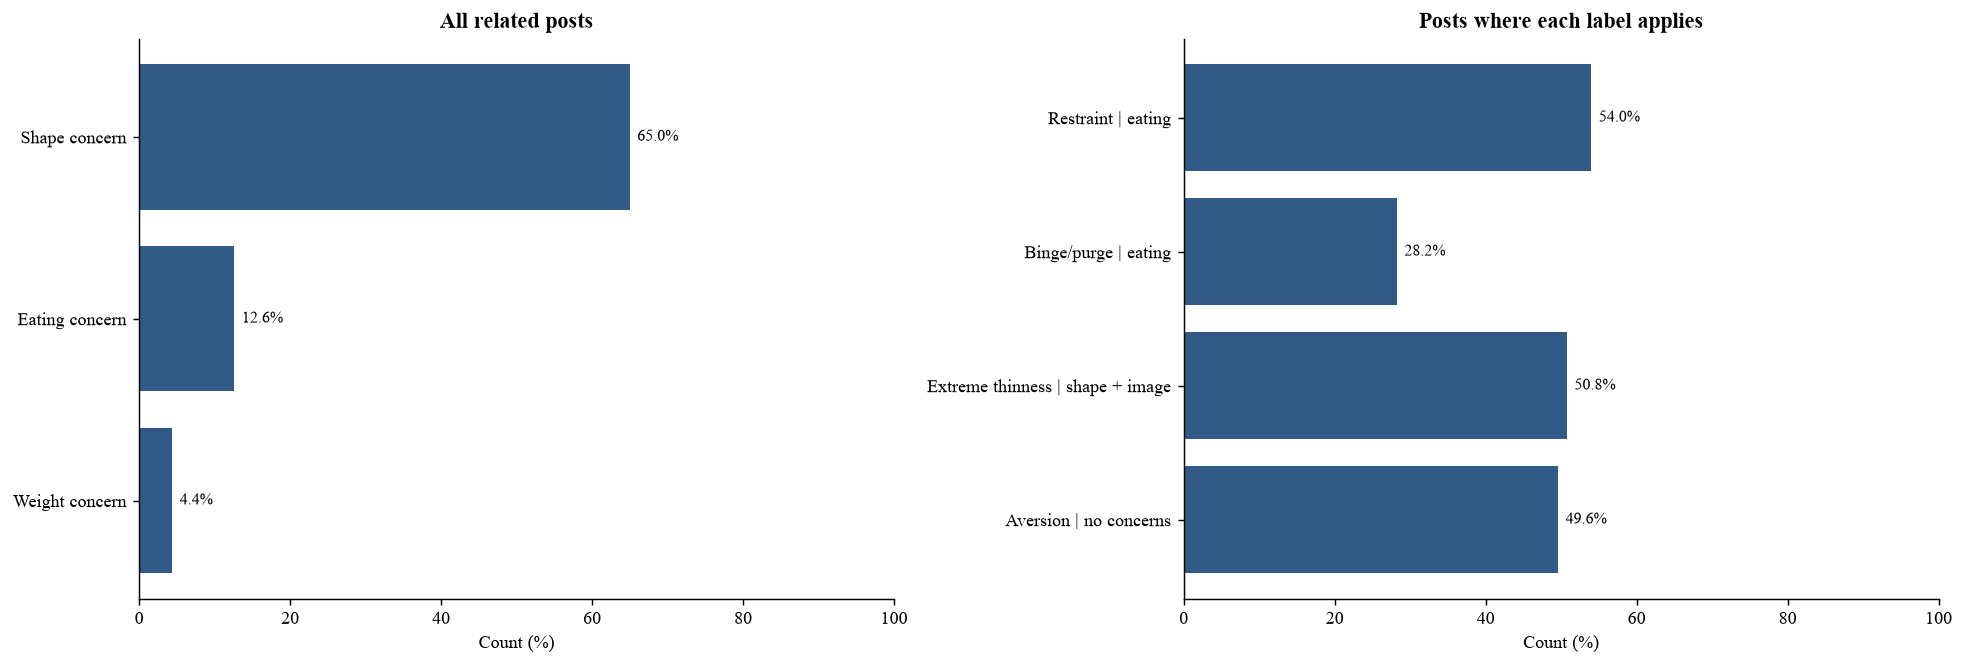

,Label,Count,Eligible posts,Percent
0,Shape concern,1679,2584,65.0
1,Eating concern,326,2584,12.6
2,Weight concern,113,2584,4.4
3,Restraint | eating,176,326,54.0
4,Binge/purge | eating,92,326,28.2
5,Extreme thinness | shape + image,437,861,50.8
6,Aversion | no concerns,297,599,49.6


In [18]:
# Same percentage scale for both panels.
figure, charts = plt.subplots(
    1, 2, figsize=(15,5), layout='constrained'
)

for chart, table, title in zip(
    charts,
    [main_concerns, other_concerns],
    ['All related posts', 'Posts where each label applies']
):
    chart.barh(table['Label'], table["Percent"], color=BLUE)
    chart.invert_yaxis()
    chart.set_xlim(0, 100)
    chart.set_xlabel('Count (%)')
    chart.set_title(title)

    for row, percent in enumerate(table["Percent"]):
        chart.text(
            percent + 1, row, f'{percent:.1f}%',
            ha='left', va='center', fontsize=9
        )

finish('01_twitter_themes')

display(pd.concat(
    [main_concerns, other_concerns], ignore_index=True
).round(1))

Shape concern appears in 1,679 of 2,584 related posts (65.0%), compared with 326 eating-concern posts (12.6%) and 113 weight-concern posts (4.4%). Restraint appears in 176 of the 326 eating-concern posts (54.0%).

Body image remains central to question 1, while eating concerns form a smaller group for question 2. These are frequencies of post labels, not rates of illness among people.

### 5.2 TikTok categories and blanks
EDTT has 79 posts with EDE category text and six with blank fields. We leave those six unknown. This section answers question 1 and explains why question 3 currently has 79 usable posts.

#### Count categories and missing labels
For each category, calculate the known-label percentage and the possible range across all 85 posts. The minimum assumes none of the six unknown posts has that category; the maximum assumes all six do.

In [19]:
# Count EDE labels without treating missing annotations as "no."
category_counts = count_labels(tiktok, {
    'ede_shape': 'Shape concern',
    'ede_eating': 'Eating concern',
    'ede_weight': 'Weight concern',
    'ede_restraint': 'Restraint'
})

missing_labels = tiktok['ede_subscale_items'].isna().sum()
total_posts=len(tiktok)

category_counts['All posts: minimum %'] = (
    100 * category_counts['Count'] / total_posts
)
category_counts['All posts: maximum %'] = (
    100 * (
        category_counts['Count'] + missing_labels
    ) / total_posts
)

#### Show what the blanks could change
Teal dots use the 79 known annotations. Blue diamonds show the recorded count divided by all 85 posts. Gray lines show the possible all-post range if the missing categories were known. These are missing-data scenarios, not confidence intervals.

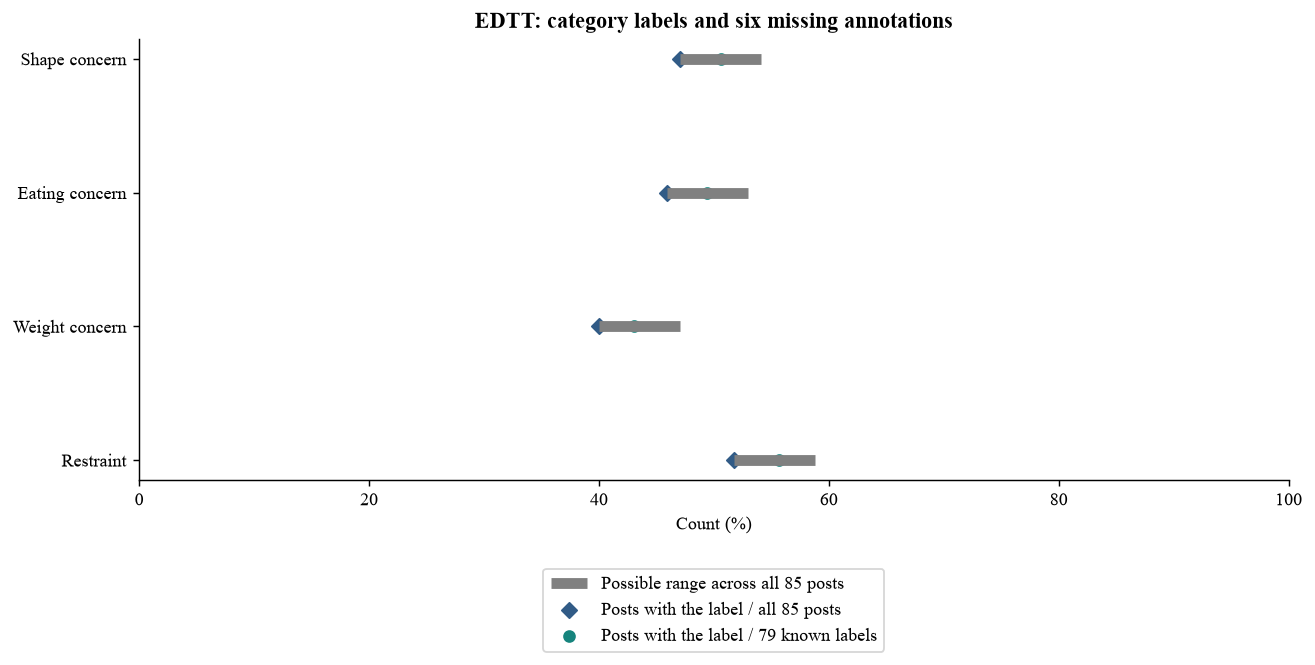

,Label,Count,Eligible posts,Percent,All posts: minimum %,All posts: maximum %
0,Shape concern,40,79,50.6,47.1,54.1
1,Eating concern,39,79,49.4,45.9,52.9
2,Weight concern,34,79,43.0,40.0,47.1
3,Restraint,44,79,55.7,51.8,58.8


In [20]:
# Gray lines show what could change if the missing labels were known.
figure, chart = plt.subplots(
    figsize=(10, 5), layout='constrained'
)

chart.hlines(
    category_counts["Label"],
    category_counts['All posts: minimum %'],
    category_counts['All posts: maximum %'],
    color='gray', linewidth=6,
    label='Possible range across all 85 posts'
)

chart.scatter(
    category_counts['All posts: minimum %'],
    category_counts["Label"],
    color=BLUE, marker='D',
    label='Posts with the label / all 85 posts'
)

chart.scatter(
    category_counts['Percent'],
    category_counts["Label"],
    color=TEAL,
    label='Posts with the label / 79 known labels'
)

chart.invert_yaxis()
chart.set_xlim(0, 100)
chart.set_xlabel('Count (%)')
chart.set_title('EDTT: category labels and six missing annotations')
chart.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18))

finish('02_edtt_ede')
display(category_counts.round(1))

Restraint is the most common recorded category: 44 of 79 posts (55.7%). Shape concern appears in 40 (50.6%), eating concern in 39 (49.4%), and weight concern in 34 (43.0%). Categories can overlap.

Each all-post range spans 7.1 percentage points because six of 85 annotations are unknown. Treating those blanks as zero would hide this uncertainty. We have not compared any EDE category with audio valence.

### 5.3 Videos and photo posts
Do visual features differ by format? We compare percentages within the 47 videos and 38 photo posts, rather than comparing raw counts between unequal groups.

#### Count features by format
The table records counts, group sizes, percentages, and the percentage-point difference. The full table is saved for checking individual values.

In [21]:
# Compare counts and percentages for videos and photo posts.
video_posts = tiktok[tiktok["type"] == 'video']
photo_posts = tiktok[tiktok["type"] == 'photos']

visual_summary = pd.DataFrame(index=visual_cols)

visual_summary['Videos with this label'] = (
    video_posts[visual_cols].sum()
)
visual_summary['Videos counted'] = len(video_posts)
visual_summary['Videos (%)'] = (
    100 * visual_summary['Videos with this label'] / len(video_posts)
)

visual_summary['Photo posts with this label'] = (
    photo_posts[visual_cols].sum()
)
visual_summary['Photo posts counted'] = len(photo_posts)
visual_summary['Photo posts (%)'] = (
    100 * visual_summary['Photo posts with this label'] / len(photo_posts)
)

visual_summary['Photo % minus video %'] = (
    visual_summary['Photo posts (%)'] - visual_summary['Videos (%)']
)

visual_summary.index = list(visual_headers.values())
visual_summary.index.name = 'Visual feature'


visual_summary.to_csv(CLEAN / 'visual_format_summary.csv')
display(visual_summary[['Videos with this label', 'Photo posts with this label', 'Videos (%)', 'Photo posts (%)']].round(1))

,Videos with this label,Photo posts with this label,Videos (%),Photo posts (%)
Visual feature,,,,
Body Checking & Self Emphasis,24,4,51.1,10.5
On-Screen Text,43,38,91.5,100.0
Performance & Body Language,37,11,78.7,28.9
Weight-Related Imagery,16,4,34.0,10.5
Food-Related Imagery,5,16,10.6,42.1
Media & Memes,10,27,21.3,71.1
Summaries & Metrics,1,14,2.1,36.8


#### Compare the formats
Each pair of bars shows one visual feature. The labels follow the source categories. This explores question 1 and supports keeping format in the planned audio model, but does not establish that format explains a restraint-valence association.

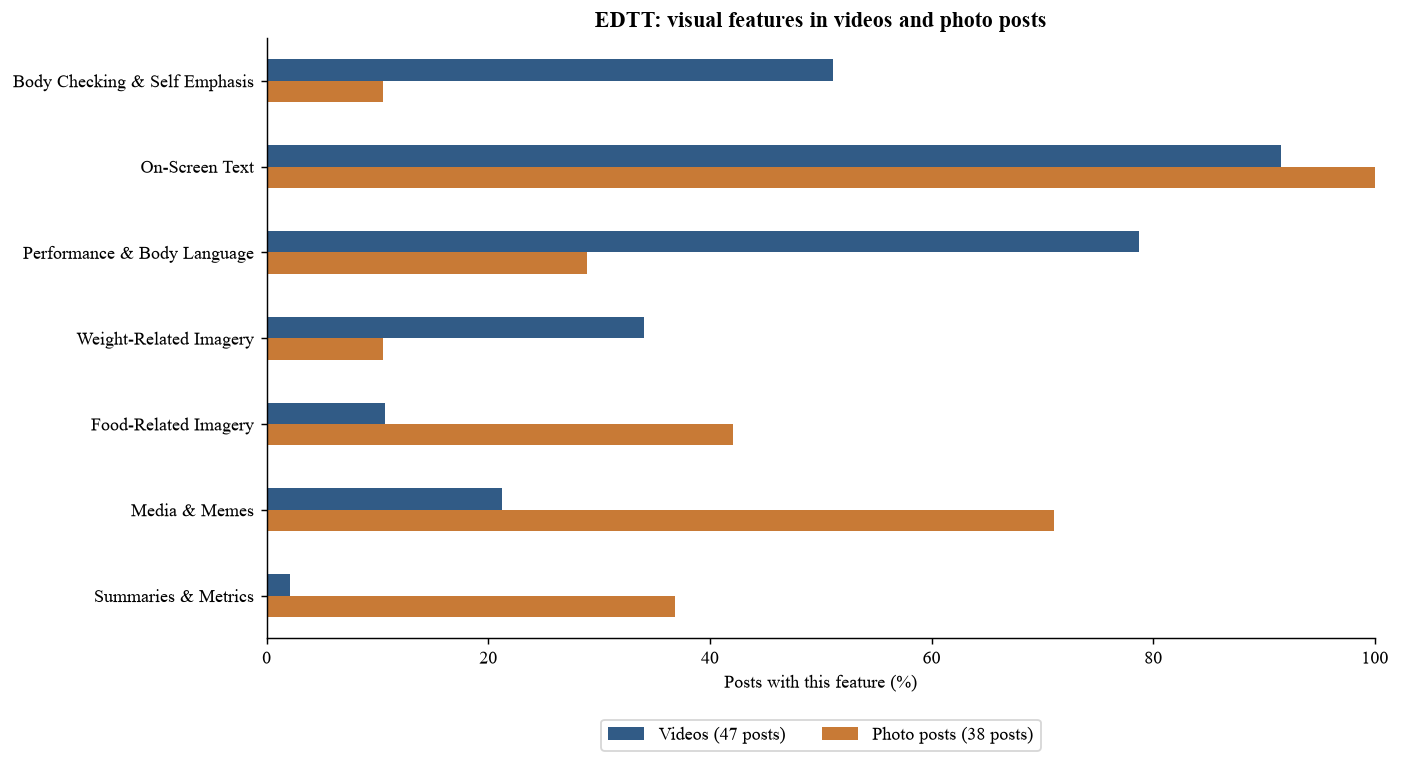

In [22]:
# Draw paired bars directly from the percentage columns.
chart = visual_summary[['Videos (%)', 'Photo posts (%)']].plot.barh(
    figsize=(11,6), color=[BLUE, ORANGE]
)

chart.invert_yaxis()
chart.set_xlim(0, 100)
chart.set_xlabel('Posts with this feature (%)')
chart.set_ylabel('')
chart.set_title('EDTT: visual features in videos and photo posts')
chart.legend(
    [
        f'Videos ({len(video_posts)} posts)',
        f'Photo posts ({len(photo_posts)} posts)'
    ],
    loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2
)

finish('03_visual_format')

Performance and body language appear in 37 of 47 videos (78.7%) and 11 of 38 photo posts (28.9%). Media and memes show the reverse pattern: 10 videos (21.3%) and 27 photo posts (71.1%). Both differences are about 49.8 percentage points, the largest gaps in this sample.

Food imagery also appears more often in photo posts: 16 of 38 (42.1%), compared with 5 of 47 videos (10.6%). These differences describe the sampled posts; changing format would not necessarily change a post's content.

### 5.4 Audio values
All 85 EDTT posts have these audio measurements. Tempo is musical speed in beats per minute. Valence estimates musical positivity; arousal estimates energy. Both use a 0-to-1 scale and do not describe a person's feelings.

#### Summarize the values
Use `describe()` to calculate averages, spread, and quartiles. The median is the middle value; the 25th and 75th percentiles bound the middle half. We save the complete table and display it in two parts for readability.

In [23]:
# Summarize audio values and give the table readable labels.
audio_columns = [
    'audio_tempo_bpm', 'audio_valence',
    'audio_arousal', 'harmonic_ratio'
]

audio_summary = tiktok[audio_columns].describe().T
audio_summary.index = [
    'Tempo (BPM)',
    'Musical positivity (valence)',
    'Musical energy (arousal)',
    'Tonal share (harmonic ratio)'
]

audio_summary = audio_summary.rename(columns={
    'count': 'Posts counted',
    'mean': 'Average',
    'std': 'Standard deviation',
    'min': 'Lowest',
    '25%': '25th percentile',
    '50%': 'Median',
    '75%': '75th percentile',
    'max': 'Highest'
})

display(audio_summary[['Posts counted', 'Average', 'Standard deviation', 'Median']].round(3))
display(audio_summary[['Lowest', '25th percentile', '75th percentile', 'Highest']].round(3))
audio_summary.to_csv(CLEAN / 'audio_summary.csv')

,Posts counted,Average,Standard deviation,Median
Tempo (BPM),85.0,126.039,20.551,123.050
Musical positivity (valence),85.0,0.590,0.261,0.736
Musical energy (arousal),85.0,0.342,0.059,0.332
Tonal share (harmonic ratio),85.0,0.742,0.185,0.789


,Lowest,25th percentile,75th percentile,Highest
Tempo (BPM),78.300,112.350,143.550,172.270
Musical positivity (valence),0.090,0.232,0.774,0.836
Musical energy (arousal),0.205,0.303,0.385,0.497
Tonal share (harmonic ratio),0.050,0.670,0.865,0.993


#### Plot the distributions
Each histogram uses ten equal-width bins across its observed values. The line marks the median. The boxplots show the middle half and possible extreme values; a point beyond a whisker is not automatically an error. We keep all rows.

Valence is the outcome for question 3. Here we examine it on its own, without separating posts by restraint status.

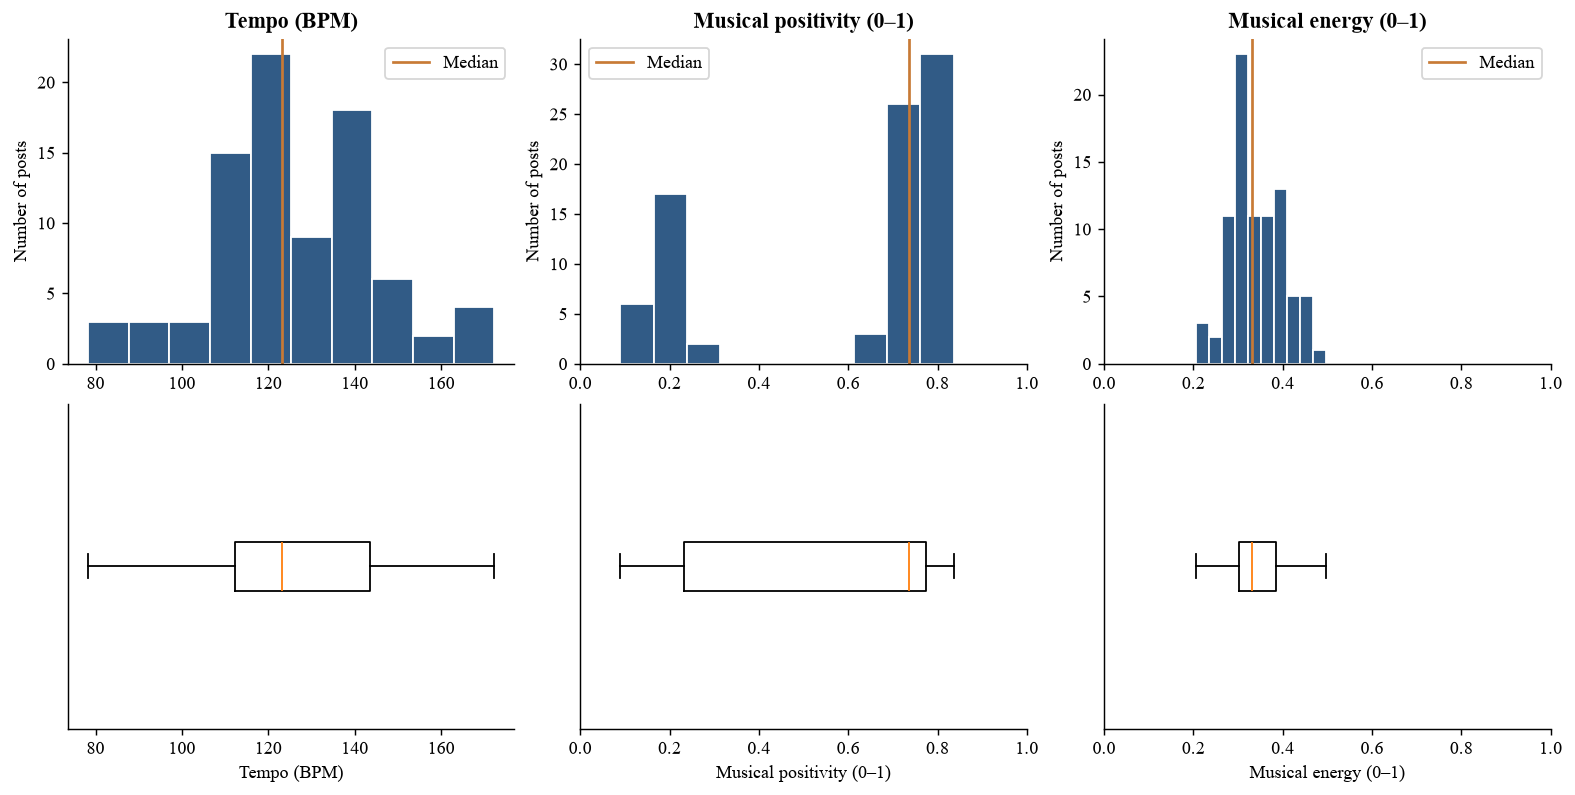

In [24]:
# Histograms show the shape; boxplots show the middle and spread.
plot_columns = [
    'audio_tempo_bpm', 'audio_valence', 'audio_arousal'
]
plot_labels = [
    'Tempo (BPM)',
    'Musical positivity (0–1)',
    'Musical energy (0–1)'
]

figure, charts = plt.subplots(
    2, 3, figsize=(12,6), layout='constrained'
)

for position, column in enumerate(plot_columns):
    values = tiktok[column]
    histogram = charts[0, position]
    boxplot = charts[1, position]

    values.hist(ax=histogram, bins=10, color=BLUE, edgecolor='white', grid=False)
    histogram.axvline(values.median(), color=ORANGE, label='Median')
    histogram.set_title(plot_labels[position])
    histogram.set_ylabel('Number of posts')
    histogram.legend()

    boxplot.boxplot(values, orientation='horizontal')

    if column != 'audio_tempo_bpm':
        histogram.set_xlim(0, 1)

    boxplot.set_xlim(histogram.get_xlim())
    boxplot.set_yticks([])
    boxplot.set_xlabel(plot_labels[position])

finish('04_audio_distributions')

Median tempo is 123.05 BPM. The middle half lies between 112.35 and 143.55 BPM; the full range is 78.30 to 172.27 BPM.

Valence has a median of 0.736 and a lower mean of 0.590. The histogram shows both a higher-score group and a smaller lower-score group, so one average misses part of the distribution. The middle half spans 0.232 to 0.774.

Arousal is more concentrated, with its middle half between 0.303 and 0.385. Its spread should not be compared directly with tempo's because the units differ. These plots help us describe the planned outcome without testing the hypothesis.

### 5.5 What the EDA tells us
We keep the three research questions and the same rows. The figures answer different parts of question 1: label frequency, uncertainty from blank annotations, visual features by format, and audio distributions.

Shape concern is the main Twitter theme, while eating concern has a smaller but usable group. EDTT adds visual and audio measures, but only 79 posts have known EDE categories. These findings support one focused analysis per source rather than many comparisons.

Questions 2 and 3 remain untested. Separate label percentages do not show whether shape and eating concerns co-occur, and the audio distributions do not show whether restraint relates to valence. Neither dataset measures algorithm exposure or changes in food attitudes.

## 6. Questions for reviewers: Part 1
These questions address issues raised in our team drafts and the data checks.

1. Should we retain the 11 inconsistent Twitter rows and compare the later model with and without them, as planned?
2. Is leaving the six blank EDTT category fields unknown appropriate? Should we ask the source authors to clarify them before changing that rule?
3. Do the two separate datasets form a coherent project about food and body-image content, despite their different collection and coding methods?
4. Do the missing-label ranges and format comparisons help explain the data, or is another descriptive comparison more useful before modeling?

## Part 2. Preregistration of future analyses
### What has been viewed
These plans follow the data audit and EDA, not an untouched dataset. We inspected source documentation, examples, the Twitter consistency check, individual-variable summaries, and visual features by format. We have not tabulated, correlated, or modeled the two planned predictor-outcome pairs.

The October 19 revision clarifies the models without changing the hypotheses or fitting them. Save a dated copy before running the analyses and document later changes.

### Reporting plan
We will report both analyses regardless of their direction or statistical significance, including counts, effect sizes, 95% confidence intervals, diagnostics, and limitations. Use two-sided tests. For the two primary p-values, apply Holm correction at 0.05 and show both original and adjusted values. The direction of each estimate determines whether it agrees with the hypothesis.

Each row remains one post. An arbitrary number of posts is not a predictor: sample size affects precision, not the content of an individual post. A larger sample also does not remove selection bias, confounding, or dependence between posts.

## 7. Preregistration 1: Twitter concerns
### Hypothesis
Among related Twitter posts, posts with a shape-concern label are more likely to have an eating-concern label. Body-image and food concerns may be expressed together, but this is a hypothesis about content, not a claim about illness or causation.

### Data and variables
Use the 2,584 rows in `twitter_related.csv`. The outcome is `eating` (0 or 1); the predictor is `shape` (0 or 1). Keep the original labels and all valid IDs. Exclude and count any missing predictor or outcome; none are currently missing. Keep the 11 flagged rows in the main analysis, then repeat it without them as a secondary check.

### Planned model
Use logistic regression because the outcome is yes/no:

`logit[P(eating = 1)] = beta_0 + beta_1 * shape`

We expect `beta_1 > 0`. Test `beta_1 = 0` with a two-sided coefficient test. Report the odds ratio `exp(beta_1)`, its 95% confidence interval, and the predicted probability for each shape group. Also report the probability difference so the result is understandable without interpreting odds. The model is fit to individual posts, not an invented total or percentage for a batch of posts.

### Checks and reporting
In the final phase, show the 2-by-2 counts and fit the model with statsmodels. Flag cells with fewer than five posts. If a cell is zero or the model fails because of separation, use a two-sided Fisher exact test and an exact odds-ratio interval instead. If either variable has no variation, report that the association cannot be estimated. Report any fallback and the secondary analysis excluding flagged rows.

Correlation and covariance between two binary labels are not needed as additional tests of the same hypothesis. Logistic regression directly addresses the planned comparison.

### Limits
The relationship may reflect shared coding practices or repeated creators. Account type and post length are unavailable; `noconcern` is determined by the concern labels and should not be used as a control. Without creator IDs, uncertainty estimates may be too narrow. We will describe an association in this sample, not a causal or population-wide effect.

## 8. Preregistration 2: Restraint and audio
### Hypothesis
EDTT posts with a recorded restraint label have lower average audio valence than posts without that label, after accounting for format. This asks whether food-restriction content has a different musical tone. The direction is uncertain: upbeat or ironic music could produce the opposite result.

### Data and variables
Use posts with nonblank EDE text and valid audio valence and format, currently 79 rows. The outcome is `audio_valence` on its 0-to-1 scale. The predictor `ede_restraint` is 1 when the Restraint header is recorded and 0 when nonblank text lacks it. Code `photos = 1` for photo slideshows and 0 for videos. Exclude the six unknown EDE rows from the primary model; do not treat blanks as confirmed absence.

### Planned model
Use linear regression with format included:

`audio_valence = beta_0 + beta_1 * ede_restraint + beta_2 * photos + error`

We expect `beta_1 < 0`. It represents the mean valence difference between restraint groups at the same format. Compare predicted valence for restraint = 0 and restraint = 1 within each format. No arbitrary post-count predictor is needed, and Twitter shape/eating correlations do not address this TikTok hypothesis.

### Checks and reporting
Fit the model with statsmodels, using HC3 robust standard errors and t-based inference (`use_t=True`). Report the coefficient, 95% interval, two-sided p-value, group sizes, R-squared, and predictions by restraint and format. Inspect residuals and influential rows; flag Cook's distance above `4/n` but keep these rows in the main model. Report predictions outside 0 to 1. If predictors have no variation or cannot be separated, report that the model cannot estimate the requested effect.

As secondary missing-data checks, repeat the model twice: assign all six unknown restraint labels to 0, then to 1. Report both estimates as scenarios, not proven bounds or replacements for the primary model. Do not remove outliers or change predictors after seeing which result is significant.

### Limits
Format is available and relevant to how posts combine images and sound; it does not account for every possible confounder. Account type, post length, and reliable creator identifiers are unavailable. Only 79 posts enter the primary analysis, not thousands. Robust standard errors address unequal residual variance, not selection bias or repeated audio. Musical valence is not a measure of a viewer's emotions or health.

## Appendix A. Data cleaning appendix and reproducibility
**Files.** data/raw/ contains unchanged source downloads and the checksum manifest. `data/intermediate/` contains validated/normalized snapshots. `data/processed/` contains analysis tables and audits. `figures/` contains the four charts. The download bundle includes these files, the executed notebook, its HTML view, and the combined PDF. In GitHub, the notebook is in notebooks/ and the report is in `reports/phase2/`.

**Re-run.** Extract the full ZIP, install the packages in `requirements.txt` in a Python environment, open this notebook from the extracted directory, select that environment's kernel, and choose Restart Kernel and Run All. A complete local bundle runs offline. A notebook opened alone in Colab needs internet access on its first run to restore the saved inputs from GitHub. Processed files and figures are overwritten reproducibly. All code cells should finish without errors. No proposed inferential analyses are implemented here.

**Hosted raw inputs.** The [verified GitHub raw-data folder](https://github.com/AnyaChoudhary/info2950-fall2026-project/tree/905e574351e821300dc5b199747216a3bd630e1b/data/raw) contains both original CSVs, the Twitter codebook and filtering appendix, and `manifest.json`. These are the exact bytes used in this execution. The publisher links in Section 2 provide independent access to the original releases.

**Cleaning trace.** Section 2.2 verifies the four original files; Section 2.3 validates Twitter codes and their conditional universes, saves all 3,000 rows, retains 2,584 related posts, and flags 11 logical inconsistencies; Section 2.4 normalizes all 85 EDTT rows and derives 11 category indicators plus a count while preserving six unknown EDE annotations; Section 2.5 saves row-flow and eligibility audits. Sections 5.1–5.4 generate the displayed summaries and figures from those analysis-ready files. Every code cell has an executed output or visible saved-file result, and the proposed inference remains unperformed.

## Appendix B. References
1. Cavazos-Rehg, P. A., et al. (2019). “I just want to be skinny.”: A content analysis of tweets expressing eating disorder symptoms. *PLOS ONE*, 14(1), e0207506. https://doi.org/10.1371/journal.pone.0207506. S1 Dataset, S1 Codebook, and S1 Appendix are bundled unchanged.
2. Shaveet, E., Viranda, T., & Choudhury, T. (2026). *EDTT Dataset*, version 2. Zenodo. https://doi.org/10.5281/zenodo.19749827. Public dictionary: https://edenshaveet.github.io/EDTT/.
3. Project repository: https://github.com/AnyaChoudhary/info2950-fall2026-project. Raw-data snapshot linked in Section 2.
4. INFO 2950, Fall 2026. *Phase II: Exploratory analysis and hypotheses*. User-supplied course rubric, read in full. Its datasheet-style prompts guide Sections 3 and 4.

## 9. Questions for reviewers: Part 2
These questions build on our team's model-choice, omitted-variable, and presentation concerns.

1. Is logistic regression the right choice for Twitter's binary outcome, and is the proposed sparse-cell fallback suitable for this course?
2. Is a linear model with format appropriate for EDTT valence, given the bounded scale and 79 usable posts? Are the planned robust intervals and residual checks sufficient?
3. With account type, post length, and creator IDs unavailable, should we narrow the interpretation further or seek additional data before modeling? We recognize that more posts alone would not remove these biases.
4. Are the two extreme assignments for the six unknown restraint labels useful sensitivity checks, or should source-author clarification take priority?
5. Are equations, variable definitions, and plain-language descriptions sufficient for the final report, or would you like additional mathematical notation?

Both planned analyses will be reported even if they do not support the hypotheses.